# 06 · Genomic footprints in tissue architecture

Genomic profiling informs many treatment decisions in oncology, yet it is not available for every patient or archival sample, whereas an H&E slide exists for virtually all of them. This notebook asks which genomic alterations leave a recognisable footprint on the organisation of the tumour and its microenvironment, as captured by the interpretable Atlas H&E-TME features of OpenTME, and how much of that footprint goes beyond molecular subtype.

Two levels of the question:
- **Practical:** what can be inferred about the genome of a tumour from the H&E slide alone, including through its association with subtype?
- **Biological:** does an alteration change the tissue by itself, at equal subtype and tumour purity?

Structure:
1. **Data:** genomic variables (including derived ones) and image features, with a rank-based transformation for skewed variables.
2. **Genomic screen:** every genomic variable (driver mutations, oncogenic pathways, chromosome-arm events, genome-wide DNA measures) against every image feature, and an image-wide permutation test per genomic variable, with permutations within subtype that preserve the correlation among image features. The screen is repeated under increasingly strict adjustment.
3. **Selected footprints** followed across adjustment levels, including a positive control when the indication has one (breast: CDH1 and lobular histology).

Parameters are in `configs/analysis.yaml` (section `genomic_footprints`) and in the indication file; functions are in `src/opentme_tcga/genomic_footprints.py` and are agnostic to the molecular variable and the cancer type. The *Observations* describe the results of the pilot indication (breast cancer).

**Outputs**: tables in `results/<indication>/06_genomic_footprints/` and figures in `figures/<indication>/06_genomic_footprints/`.

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

from opentme_tcga.config import ensure_dirs, load_config
from opentme_tcga.genomic_footprints import (
    MolecularTarget, discover_targets, effects_across_adjustments,
    footprint_screen, footprints_by_adjustment, omnibus_permutation_test, plot_adjustment_bars,
    plot_effects_across_adjustments, plot_feature_by_group, plot_footprints_by_adjustment, plot_omnibus,
    rank_inverse_normal, resolve_terms, select_image_features, tissue_footprint, two_hit,
)
from opentme_tcga.tcga import load_labels, make_label

INDICATION = "breast"          # name of a file in configs/indications/

cfg = load_config(INDICATION)
P = cfg["paths"]
GF = cfg["genomic_footprints"]
SUB = cfg["tcga_molecular"]["subtypes"]

OUT_DIR = P["results"] / "06_genomic_footprints"
FIGS = P["figures"] / "06_genomic_footprints"
ensure_dirs(cfg)
FIGS.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Configuration

Column names and settings come from the configuration; here they only get short names. Covariate sets are written with the aliases `subtype` and `purity`; the main model is subtype + purity, and subtype also defines the permutation strata.

In [2]:
SUBTYPE, SUBTYPE_LABEL = SUB["column"], SUB["label"]
PURITY = cfg["immune_phenotypes"]["molecular"]["purity"]
ALIASES = {"subtype": f"C({SUBTYPE})", "purity": PURITY}

IMG_CFG, GEN_CFG = GF["image"], GF["genomic_screen"]
TRANSFORM, EXPOSURE_TRANSFORM = IMG_CFG["transform"], GEN_CFG["exposure_transform"]
ALPHA = GEN_CFG["fdr_alpha"]
COVARIATES = resolve_terms(["subtype", "purity"], ALIASES)
ADJUSTMENTS = {name: resolve_terms(terms, ALIASES) for name, terms in GEN_CFG["adjustments"].items()}
ADJ_LABELS = list(ADJUSTMENTS)
STRICTEST = ADJ_LABELS[-1]

TWO_HIT = GF["derived"]["two_hit"]
SELECTED = GF["selected_footprints"]
PC = GF["positive_control"]

LABELS = load_labels(P["configs"] / "variable_labels.yaml")
pretty_label = lambda col: make_label(col, LABELS) or col
print("Main model:", " + ".join(COVARIATES))
for name, covs in ADJUSTMENTS.items():
    print(f"  {name}: {' + '.join(covs)}")

Main model: C(clin_pam50) + abs_purity
  purity only: abs_purity
  subtype + purity: C(clin_pam50) + abs_purity
  subtype + purity + histology: C(clin_pam50) + abs_purity + C(clin_histology)


## 2. Data

### 2.1 Integrated table

One row per patient (notebook 03): the OpenTME master table joined with the TCGA molecular and clinical variables. Mutation status is missing for patients who were not sequenced, so each genomic variable is analysed in the patients for whom it is defined. Image feature names are taken from the OpenTME master table itself, which keeps the separation between image and molecular variables explicit.

In [3]:
df = pd.read_parquet(P["integrated"])
opentme_columns = pq.read_schema(P["opentme_patients"]).names
print(f"{len(df)} patients, {df.shape[1]} columns; {len(opentme_columns)} columns in the OpenTME table")

1025 patients, 756 columns; 647 columns in the OpenTME table


### 2.2 Derived genomic variables

- **Log scale:** tumour mutational burden is highly right-skewed, with a few hypermutated tumours that would dominate a linear model; it is kept on a log10(1 + x) scale for interpretation (`derived.log10p1`).
- **Two hits** (`derived.two_hit`): inactivation of a tumour suppressor typically requires a mutation in one allele and loss of the chromosome arm carrying the other. A tumour with both events is a closer approximation to complete loss than mutation status alone, and enters the screen as a binary variable (breast: CDH1 mutation + 16q loss).

TMB remains skewed even after the logarithm, so all continuous genomic variables are rank-based inverse normal transformed within each analysis, the same treatment as the image features: no small group of extreme tumours can drive an association.

In [4]:
for col in GF["derived"]["log10p1"]:
    df[f"{col}_log10"] = np.log10(1 + df[col])
for name, spec in TWO_HIT.items():
    df[name] = two_hit(df[spec["mutation"]], df[spec["arm_loss"]])
    defined = df[name].notna()
    print(f"{name}: defined for {defined.sum()} patients, {int(df[name].sum())} with both hits")
    display(pd.crosstab(df.loc[defined, spec["mutation"]], df.loc[defined, spec["arm_loss"]], margins=True))

# Every column named in the configuration must exist
required = [SUBTYPE, PURITY, "mut_profiled", *GEN_CFG["continuous"],
            *[s["variable"] for s in SELECTED]]
required += [t.removeprefix("C(").removesuffix(")") for covs in ADJUSTMENTS.values() for t in covs]
missing_cols = sorted(set(required) - set(df.columns))
assert not missing_cols, f"Missing columns: {missing_cols}"

# Skewness of the continuous genomic variables, before the rank-based transformation
raw_continuous = list(dict.fromkeys([*GF["derived"]["log10p1"], *GEN_CFG["continuous"]]))
print(f"Transformation of continuous genomic variables: {EXPOSURE_TRANSFORM}")
display(df[raw_continuous].skew().round(2).rename("skewness").to_frame())

cdh1_two_hit: defined for 772 patients, 99 with both hits


aneu_16q_loss,0.0,1.0,All
mut_CDH1,,,
0.0,267,398,665
1.0,8,99,107
All,275,497,772


Transformation of continuous genomic variables: rank_normal


,skewness
thor_tmb,13.81
thor_aneuploidy_score,0.43
thor_tmb_log10,2.54
thor_hrd,1.03
thor_heterogeneity,1.53


### 2.3 Image features

Candidates are all numeric columns of the OpenTME master table. Removed:
- absolute counts and areas, which mainly reflect the amount of tissue on the slide, and scanner metadata;
- technical quality-control readouts;
- features with more than 20 % missing values, or in which a single value covers more than 95 % of patients (this keeps informative binary features such as the presence of TLS).

None of these filters uses the molecular variables, so the selection is independent of the results.

In [5]:
IMAGE_FEATURES = select_image_features(
    df, opentme_columns, drop_prefixes=IMG_CFG["drop_prefixes"], drop_substrings=IMG_CFG["drop_substrings"],
    drop_columns=IMG_CFG["drop_columns"], max_missing=IMG_CFG["max_missing"],
    max_dominant_fraction=IMG_CFG["max_dominant_fraction"],
)
print(f"{len(IMAGE_FEATURES)} image features retained out of {len(opentme_columns)} OpenTME columns")
display(pd.Series(IMAGE_FEATURES).str.split("_").str[0].value_counts().rename("features").to_frame())

380 image features retained out of 647 OpenTME columns


,features
AVG,110
DENSITY,100
RATIO,98
CELL,46
NUCLEUS,18
RELATIVE,4
DERIVED,4


Many image features are strongly right-skewed: measurements of rare cell types, vessels or TLS are zero or close to zero in most slides and large in a few, and a handful of such slides can create or inflate an association in a linear model. Each image feature is therefore mapped to a normal distribution through its ranks (rank-based inverse normal transformation) before standardisation, a common choice in large-scale association screens. Effects remain in standard deviations, now of the transformed feature.

|skewness| > 1: 217 of 380 features; > 3: 89
Transformation of image features: rank_normal


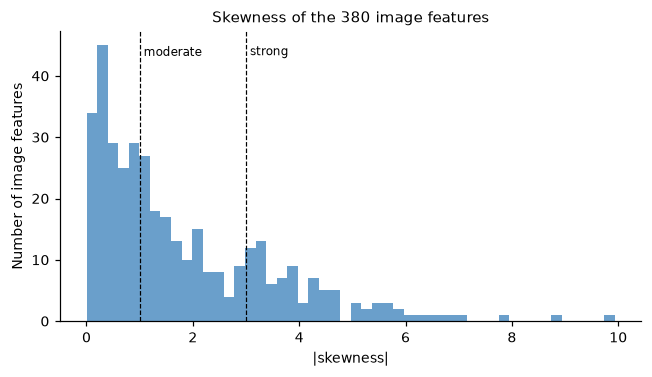

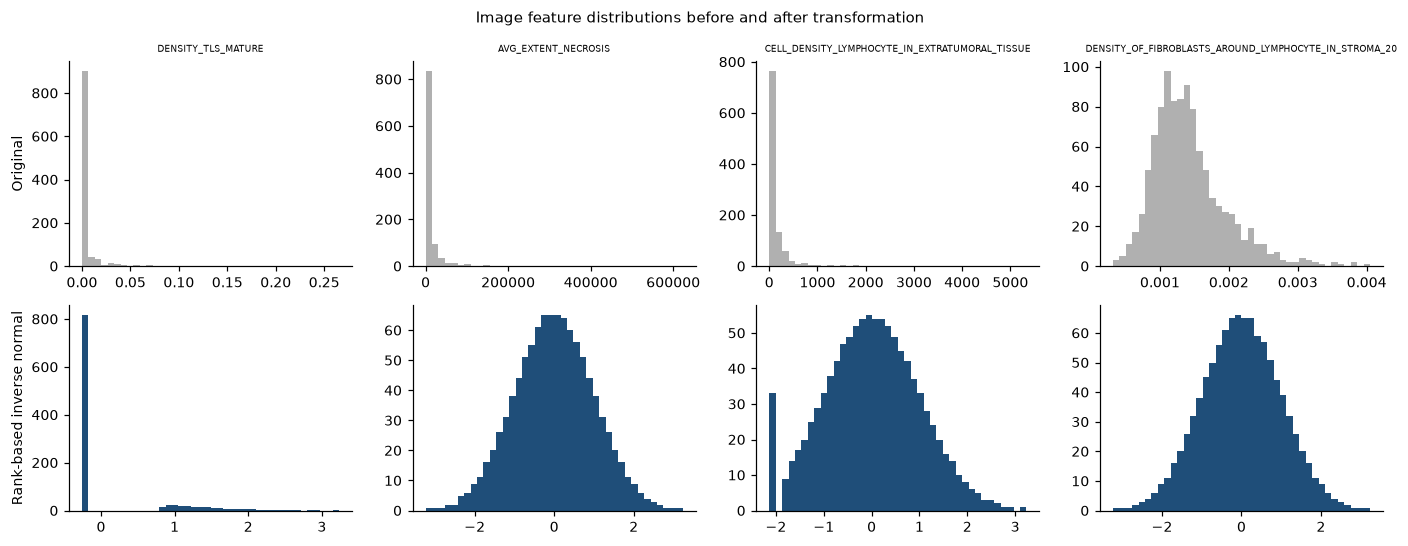

In [6]:
skewness = df[IMAGE_FEATURES].skew().abs()
print(f"|skewness| > 1: {(skewness > 1).sum()} of {len(skewness)} features; > 3: {(skewness > 3).sum()}")
print(f"Transformation of image features: {TRANSFORM}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(skewness, bins=50, color="#6a9fcb")
for x, label in [(1, "moderate"), (3, "strong")]:
    ax.axvline(x, color="black", ls="--", lw=0.8)
    ax.text(x, ax.get_ylim()[1] * 0.95, f" {label}", fontsize=8, va="top")
ax.set_xlabel("|skewness|")
ax.set_ylabel("Number of image features")
ax.set_title(f"Skewness of the {len(IMAGE_FEATURES)} image features", fontsize=10)
fig.tight_layout()
fig.savefig(FIGS / "image_feature_skewness.png", bbox_inches="tight")
plt.show()

# The three most skewed features and a typical one, before and after the transformation
examples = list(skewness.sort_values(ascending=False).index[:3]) + [(skewness - skewness.median()).abs().idxmin()]
fig, axes = plt.subplots(2, len(examples), figsize=(3.2 * len(examples), 5))
for j, feat in enumerate(examples):
    axes[0, j].hist(df[feat].dropna(), bins=40, color="#b0b0b0")
    axes[0, j].set_title(feat, fontsize=6)
    axes[1, j].hist(rank_inverse_normal(df[feat]).dropna(), bins=40, color="#1f4e79")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Rank-based inverse normal")
fig.suptitle("Image feature distributions before and after transformation", fontsize=10)
fig.tight_layout()
fig.savefig(FIGS / "image_feature_transformation_examples.png", bbox_inches="tight")
plt.show()

Features in which most slides are zero do not become perfectly normal: all zeros share the same rank and therefore the same transformed value. The transformation preserves the order of the slides but cannot create differences where the data have none.

## 3. Genomic screen

### 3.1 Genomic variables

Taken from their column prefixes (driver mutations `mut_`, chromosome-arm events `aneu_`, oncogenic pathways `path_`), plus the derived two-hit variables and four genome-wide DNA measures from Thorsson et al. (2018): aneuploidy score, tumour mutational burden, homologous recombination deficiency and intratumour heterogeneity. Binary variables with fewer than `min_altered` altered or non-altered cases are excluded, since their footprint cannot be estimated reliably.

In [7]:
GENOMIC_TARGETS = discover_targets(
    df, binary_prefixes=GEN_CFG["binary_prefixes"] + list(TWO_HIT), continuous=GEN_CFG["continuous"],
    exclude=GEN_CFG["exclude"], min_altered=GEN_CFG["min_altered"],
)
display(pd.DataFrame([{
    "target": t.name, "label": pretty_label(t.name), "kind": t.kind, "n": int(df[t.variable].notna().sum()),
    "n_altered": int(df[t.variable].sum()) if t.kind == "binary" else np.nan,
} for t in GENOMIC_TARGETS]))

,target,label,kind,n,n_altered
0,mut_TP53,TP53 mutation,binary,956,331.0
1,mut_PIK3CA,PIK3CA mutation,binary,956,328.0
2,mut_GATA3,GATA3 mutation,binary,956,117.0
3,mut_CDH1,CDH1 mutation,binary,956,115.0
4,mut_KMT2C,KMT2C mutation,binary,956,83.0
5,mut_MAP3K1,MAP3K1 mutation,binary,956,82.0
6,mut_PTEN,PTEN mutation,binary,956,57.0
7,path_cell_cycle,Cell cycle pathway altered,binary,743,357.0
8,path_hippo,Hippo pathway altered,binary,921,81.0
9,path_myc,MYC pathway altered,binary,921,197.0


### 3.2 Pairwise associations

Each image feature is regressed on each genomic variable, adjusting for subtype and tumour purity. Effects are in standard deviations of the image feature (per standard deviation of the exposure for continuous variables). Missing image values, capped at 20 % per feature, are set to the cohort mean, which slightly shrinks effects but keeps the screen on a common set of patients per genomic variable. FDR is controlled within each genomic variable (`q_within`) and across the full screen (`q_global`).

In [8]:
screen = footprint_screen(df, GENOMIC_TARGETS, IMAGE_FEATURES, COVARIATES, transform=TRANSFORM,
                          exposure_transform=EXPOSURE_TRANSFORM)
screen.to_csv(OUT_DIR / "genomic_screen_pairwise.csv", index=False)

hits = screen[screen["q_global"] < ALPHA]
print(f"{len(hits)} of {len(screen)} pairs significant at global q < {ALPHA}")
display(hits.groupby("target").size().sort_values(ascending=False).rename(f"features with q < {ALPHA}").to_frame())

1291 of 11400 pairs significant at global q < 0.05


,features with q < 0.05
target,
mut_CDH1,166
cdh1_two_hit,154
thor_tmb_log10,141
thor_hrd,114
mut_TP53,98
path_tp53,90
aneu_16q_loss,87
thor_heterogeneity,77
aneu_17p_loss,75


### 3.3 Image-wide footprint per genomic variable

Counting significant pairs overstates the evidence: image features are strongly correlated and one biological change can surface in many of them. The image-wide test summarises, for each genomic variable, the squared t-statistics across all features:
- **mean t²**, sensitive to diffuse footprints spread over many features;
- **max t²**, sensitive to sparse footprints concentrated in a few.

The null distribution comes from permuting the genomic variable within subtypes, which preserves the subtype composition and the correlation among image features: a significant result indicates a footprint beyond subtype. The two permutation p-values are combined (Bonferroni) and FDR is controlled across genomic variables.

,target,kind,n,n_altered,mean_t2,mean_t2_enrichment,p_mean_t2,max_t2,max_t2_enrichment,p_max_t2,top_feature,p_perm,q_perm
0,mut_TP53,binary,904,318.0,6.772,7.453,0.001,43.364,5.738,0.001,RATIO_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_...,0.002,0.005
1,thor_tmb_log10,continuous,952,NaN,8.152,8.607,0.001,46.184,5.903,0.001,RATIO_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_...,0.002,0.005
2,thor_aneuploidy_score,continuous,955,NaN,4.457,4.851,0.001,47.140,6.002,0.001,NUCLEUS_AVG_AREA_CARCINOMA_CELL,0.002,0.005
3,cdh1_two_hit,binary,764,99.0,11.499,12.726,0.001,109.892,14.050,0.001,AVG_MIN_DISTANCE_OF_ENDOTHELIAL_CELLS_AROUND_C...,0.002,0.005
4,aneu_8q_gain,binary,770,394.0,2.226,2.361,0.014,29.531,3.719,0.001,RATIO_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_...,0.002,0.005
5,aneu_8p_loss,binary,837,413.0,2.939,3.184,0.003,28.279,3.610,0.001,RATIO_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_...,0.002,0.005
6,aneu_17p_loss,binary,857,528.0,4.090,4.376,0.001,23.540,2.973,0.001,CELL_PERCENTAGE_GRANULOCYTE_IN_CARCINOMA,0.002,0.005
7,aneu_16q_loss,binary,812,526.0,4.946,5.439,0.001,39.477,5.169,0.001,RATIO_OF_CARCINOMA_CELLS_AROUND_LYMPHOCYTE_IN_...,0.002,0.005
8,thor_hrd,continuous,955,NaN,5.887,6.187,0.001,34.717,4.432,0.001,AVG_MIN_DISTANCE_OF_ENDOTHELIAL_CELLS_AROUND_E...,0.002,0.005
9,path_tp53,binary,893,420.0,5.515,6.080,0.001,40.250,5.209,0.001,RATIO_OF_MACROPHAGES_AROUND_LYMPHOCYTE_IN_CARC...,0.002,0.005


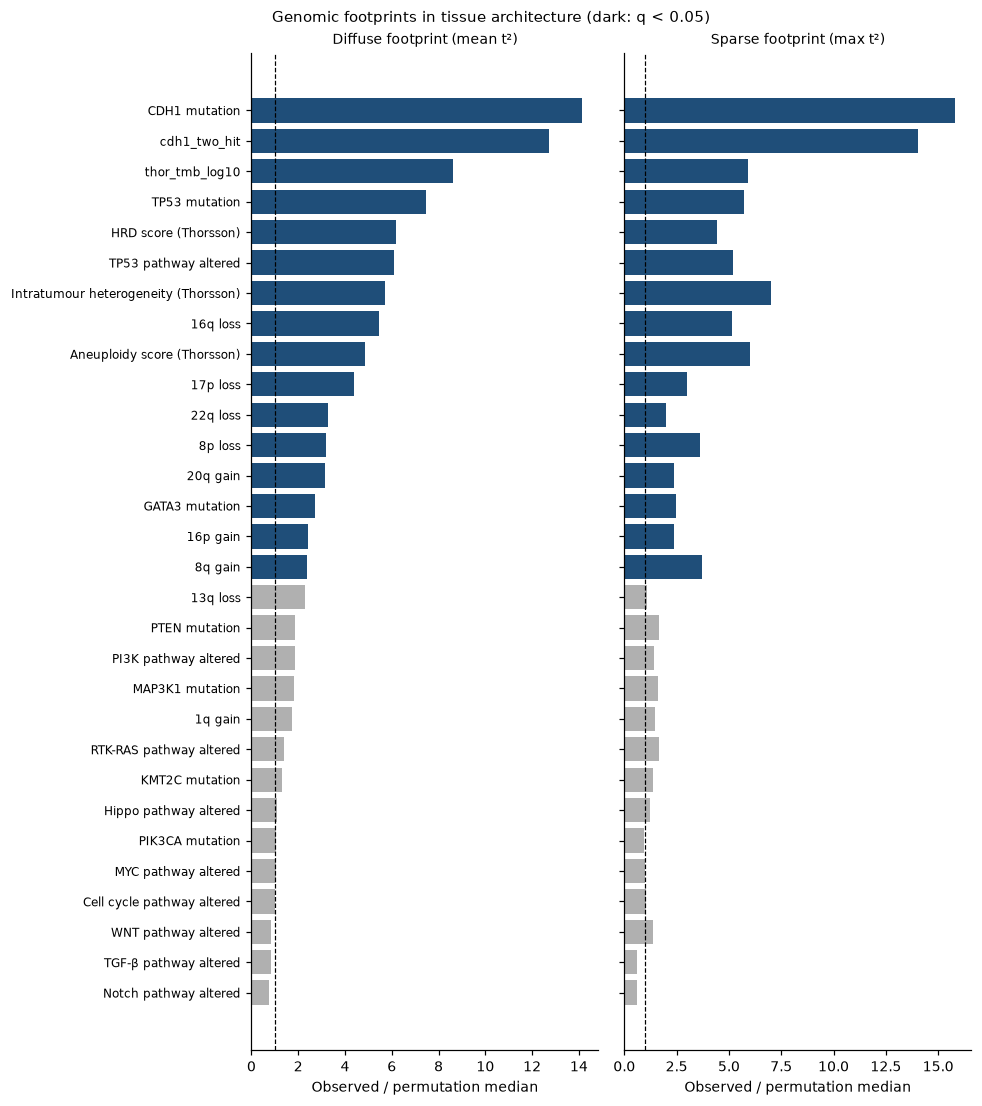

In [9]:
omnibus = omnibus_permutation_test(df, GENOMIC_TARGETS, IMAGE_FEATURES, COVARIATES, n_perm=GEN_CFG["n_perm"],
                                   seed=GEN_CFG["seed"], transform=TRANSFORM, exposure_transform=EXPOSURE_TRANSFORM)
omnibus.to_csv(OUT_DIR / "genomic_screen_omnibus.csv", index=False)
display(omnibus.round(3))

fig = plot_omnibus(omnibus, alpha=ALPHA, label=pretty_label)
fig.savefig(FIGS / "genomic_screen_omnibus.png", bbox_inches="tight")
plt.show()

**Sensitivity:** the image-wide test repeated on the untransformed image features (genomic variables treated as in the main analysis). Conclusions that hold under both versions do not depend on the distribution of the features or on a few extreme slides.

In [10]:
omnibus_raw = omnibus_permutation_test(df, GENOMIC_TARGETS, IMAGE_FEATURES, COVARIATES, n_perm=GEN_CFG["n_perm"],
                                       seed=GEN_CFG["seed"], transform=None, exposure_transform=EXPOSURE_TRANSFORM)
sensitivity = omnibus.set_index("target")[["q_perm"]].join(
    omnibus_raw.set_index("target")[["q_perm"]], rsuffix="_untransformed")
sensitivity["agree"] = (sensitivity["q_perm"] < ALPHA) == (sensitivity["q_perm_untransformed"] < ALPHA)
sensitivity.to_csv(OUT_DIR / "genomic_screen_omnibus_sensitivity.csv")
print(f"Same conclusion for {sensitivity['agree'].sum()} of {len(sensitivity)} genomic variables")
display(sensitivity.round(3))

Same conclusion for 30 of 30 genomic variables


/var/folders/8d/p5sp7fkn5r1cs9vp501_6zl00000gn/T/ipykernel_86217/3728864242.py:3: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  sensitivity = omnibus.set_index("target")[["q_perm"]].join(


,q_perm,q_perm_untransformed,agree
target,,,
mut_TP53,0.005,0.005,True
thor_tmb_log10,0.005,0.005,True
thor_aneuploidy_score,0.005,0.005,True
cdh1_two_hit,0.005,0.005,True
aneu_8q_gain,0.005,0.005,True
aneu_8p_loss,0.005,0.020,True
aneu_17p_loss,0.005,0.005,True
aneu_16q_loss,0.005,0.005,True
thor_hrd,0.005,0.005,True


### 3.4 Leading features of each footprint

For every genomic variable with a significant image-wide footprint, the ten significant features with the strongest association show which aspect of tissue organisation changes. Correlated features share the same signal, so several leading features often describe one change.

In [11]:
with_footprint = omnibus.loc[omnibus["q_perm"] < ALPHA, "target"].tolist()
leading = (screen[screen["target"].isin(with_footprint) & (screen["q_within"] < ALPHA)]
           .assign(abs_t=lambda d: d["t"].abs())
           .sort_values(["target", "abs_t"], ascending=[True, False])
           .groupby("target").head(10)[["target", "feature", "effect", "q_within"]])
leading.to_csv(OUT_DIR / "genomic_screen_leading_features.csv", index=False)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", None):
    display(leading.round(3))

,target,feature,effect,q_within
7609,aneu_16p_gain,AVG_SOLIDICITY_NECROSIS,0.298,0.004
7858,aneu_16p_gain,AVG_MIN_DISTANCE_OF_LYMPHOCYTES_AROUND_LYMPHOCYTE_IN_CARCINOMA_20,0.297,0.004
7607,aneu_16p_gain,AVG_ECCENTRICITY_NECROSIS,-0.274,0.008
7618,aneu_16p_gain,NUCLEUS_AVG_MAJ_AXIS,0.267,0.008
7849,aneu_16p_gain,AVG_MIN_DISTANCE_OF_LYMPHOCYTES_AROUND_ENDOTHELIAL_CELL_IN_CARCINOMA_20,0.269,0.008
7620,aneu_16p_gain,NUCLEUS_AVG_AREA_CARCINOMA_CELL,0.237,0.013
7616,aneu_16p_gain,NUCLEUS_AVG_AREA,0.237,0.023
7771,aneu_16p_gain,AVG_MIN_DISTANCE_OF_FIBROBLASTS_AROUND_GRANULOCYTE_IN_CARCINOMA_20,-0.236,0.024
6190,aneu_16q_loss,RATIO_OF_CARCINOMA_CELLS_AROUND_LYMPHOCYTE_IN_STROMA_20,0.410,0.000
6106,aneu_16q_loss,CELL_PERCENTAGE_CARCINOMA_CELL_IN_STROMA,0.397,0.000


### 3.5 Footprints under increasing adjustment

The subtype-adjusted screen asks a biological question: does an alteration change the tissue beyond what its association with subtype already implies? A practical question is equally relevant: what can be inferred about the genome from the H&E slide alone, directly or through subtype? Subtyping requires an expression assay or an immunohistochemical surrogate, whereas an H&E slide is always available, so a footprint that operates through subtype still carries useful information.

The pairwise screen is therefore repeated under the covariate sets of `adjustments`, from the least to the most adjusted:
- **purity only:** everything the image reveals about each alteration, including through subtype;
- **subtype + purity:** what the alteration adds beyond subtype;
- further levels set by the indication (breast: **+ histology**, which separates alterations tightly linked to a histological type, notably CDH1 and lobular carcinoma).

Reading: a large footprint that largely disappears with adjustment is mainly the tissue signature of its subtype (useful for prediction from H&E, but not specific to the alteration); a footprint that is retained belongs to the alteration itself. The `retained_` columns give the share of the least-adjusted footprint kept at each level.

adjustment,purity only,subtype + purity,subtype + purity + histology,retained_subtype + purity,retained_subtype + purity + histology
target,,,,,
mut_TP53,324,98,77,0.30,0.24
thor_hrd,321,114,66,0.36,0.21
path_tp53,305,90,75,0.30,0.25
thor_tmb_log10,292,141,116,0.48,0.40
thor_heterogeneity,272,77,53,0.28,0.19
aneu_17p_loss,250,75,55,0.30,0.22
aneu_13q_loss,239,12,4,0.05,0.02
mut_CDH1,236,166,10,0.70,0.04
aneu_8p_loss,227,36,13,0.16,0.06


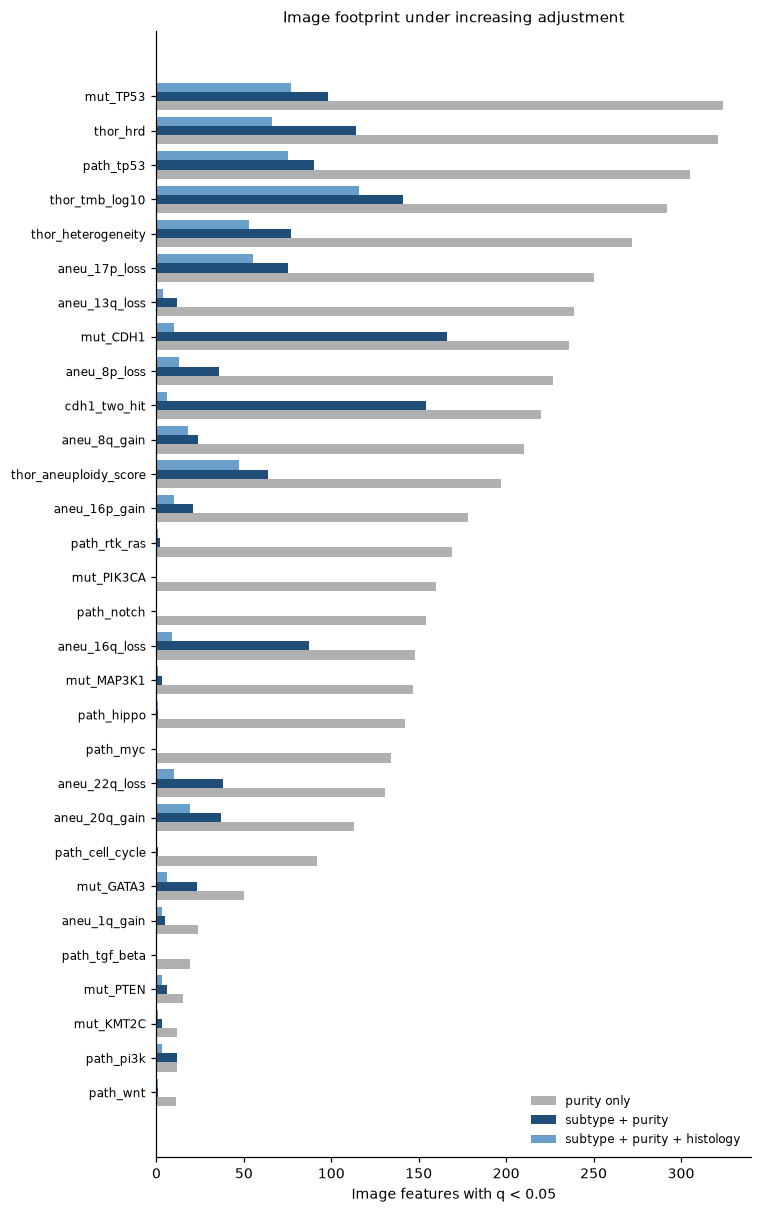

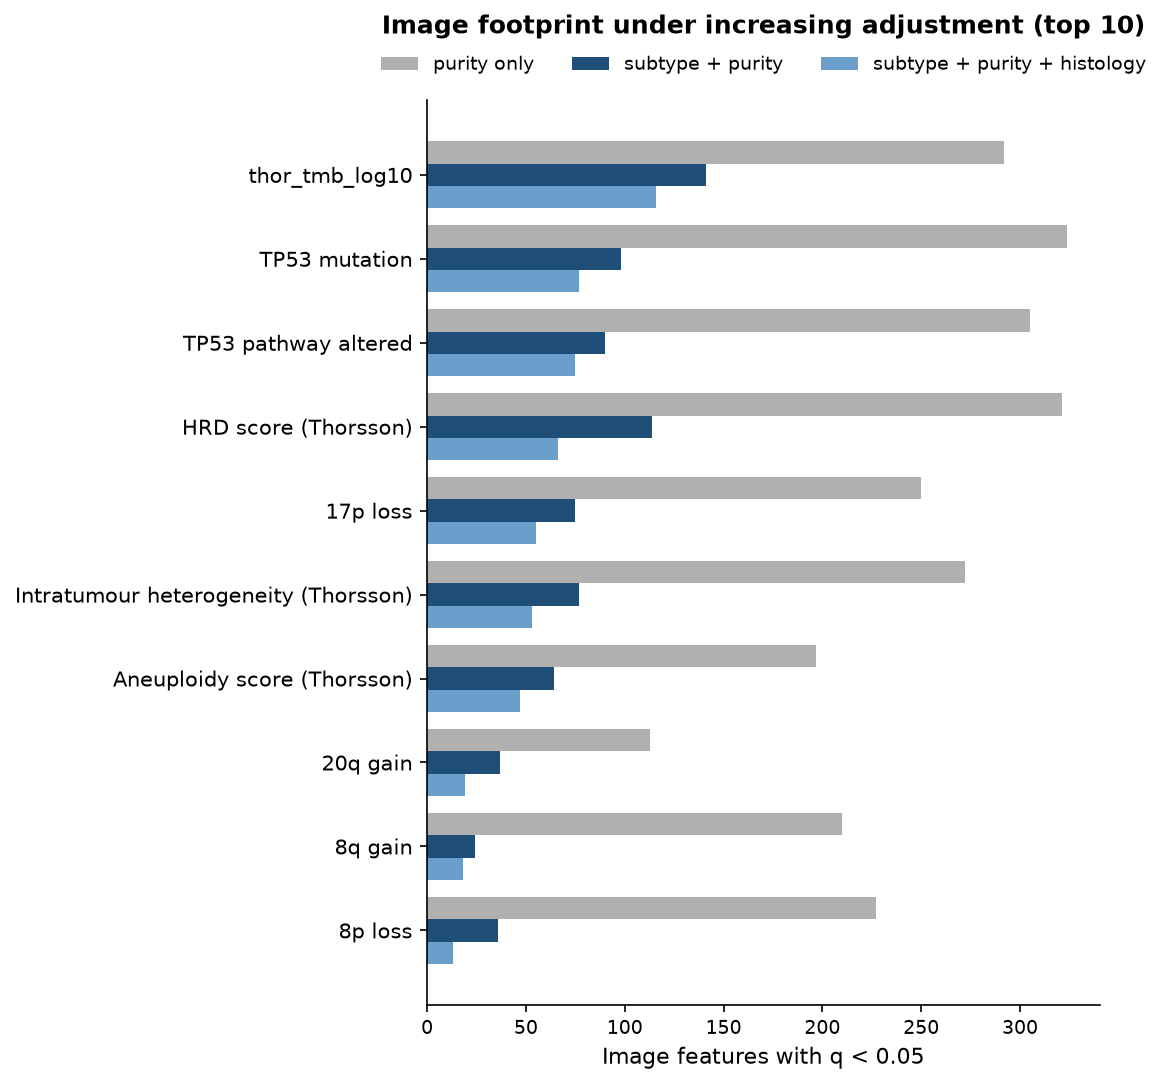

In [12]:
screens_by_adjustment, adjustment_summary = footprints_by_adjustment(
    df, GENOMIC_TARGETS, IMAGE_FEATURES, ADJUSTMENTS, alpha=ALPHA, transform=TRANSFORM,
    exposure_transform=EXPOSURE_TRANSFORM)
screens_by_adjustment.to_csv(OUT_DIR / "genomic_screen_pairwise_by_adjustment.csv", index=False)
adjustment_summary.to_csv(OUT_DIR / "genomic_screen_adjustment_summary.csv")
display(adjustment_summary)

fig = plot_footprints_by_adjustment(adjustment_summary, ADJ_LABELS)
fig.savefig(FIGS / "genomic_screen_by_adjustment.png", bbox_inches="tight")
plt.show()

# The genomic variables with the largest footprint under the strictest adjustment
top = adjustment_summary[STRICTEST].sort_values(ascending=False).head(GF["top_bars"]).index.tolist()
fig = plot_adjustment_bars(adjustment_summary, top, ADJ_LABELS, alpha=ALPHA, label=pretty_label,
                           title=f"Image footprint under increasing adjustment (top {len(top)})")
fig.savefig(FIGS / "genomic_screen_by_adjustment_top.png", bbox_inches="tight")
plt.show()

## 4. Selected footprints across adjustment levels

A few footprints (`selected_footprints`) are followed in detail through the adjustment levels of section 3.5. For each one, the effects of its leading features (selected in the strictest model) are traced from the least to the most adjusted model: a feature whose effect is stable across levels belongs to the alteration itself, whereas one whose effect shrinks was carried by subtype or histology.

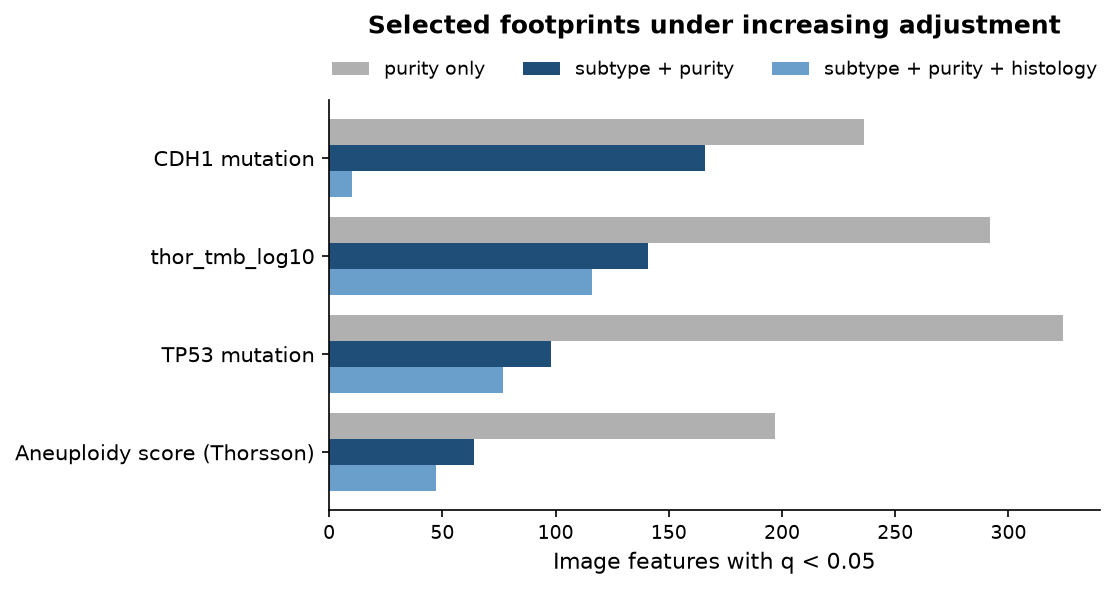

In [13]:
def show_footprint(name, variable):
    # Leading features of the strictest model, with their effects under every adjustment
    effects = effects_across_adjustments(screens_by_adjustment, variable, ADJ_LABELS, select_in=STRICTEST,
                                         alpha=ALPHA, top_n=GF["top_features"])
    slug = name.lower().replace(" ", "_")
    effects.to_csv(OUT_DIR / f"selected_{slug}_effects_across_adjustments.csv")
    with pd.option_context("display.max_colwidth", None):
        display(effects.round(3))
    if len(effects):
        fig = plot_effects_across_adjustments(effects, ADJ_LABELS,
                                              title=f"{name}: leading features under increasing adjustment")
        fig.savefig(FIGS / f"selected_{slug}_effects_across_adjustments.png", bbox_inches="tight")
        plt.show()
    else:
        print(f"{name}: no feature significant under '{STRICTEST}'")
    return effects


selected_targets = {s["name"]: s["variable"] for s in SELECTED}
in_screen = set(adjustment_summary.index)
fig = plot_adjustment_bars(adjustment_summary, [v for v in selected_targets.values() if v in in_screen], ADJ_LABELS,
                           alpha=ALPHA, label=pretty_label, title="Selected footprints under increasing adjustment")
fig.savefig(FIGS / "selected_footprints_by_adjustment.png", bbox_inches="tight")
plt.show()

### 4.1 Positive control

Configured in `positive_control` (breast: **CDH1**). Loss of E-cadherin reduces adhesion between tumour cells, which grow as discohesive single cells and files, the hallmark of lobular carcinoma. Because CDH1 inactivation and lobular histology almost coincide, the footprint is expected to persist after adjustment for subtype and to collapse after adjustment for histology. The features that survive the histology adjustment show what, if anything, the image sees of the alteration beyond the pathologist's diagnosis.

The most direct test separates the alteration from the histological type, with three comparisons on pre-specified cohesion features (chosen from the biology of E-cadherin, not from the ranking of the screen):
1. **Mutation, whole cohort**, additionally adjusted for histology.
2. **Two hits vs. other tumours of the typical histology** (breast: lobular). Many of the latter have probably lost E-cadherin through mechanisms not captured here, such as promoter methylation, so a smaller difference is expected.
3. **Arm loss alone vs. none, in the other histology without mutation** (breast: ductal, CDH1 wild type). One functional copy remains, so no difference is expected: a negative control.

Positive control (section 4.1). Its footprint is expected to persist after adjustment for subtype and to collapse after adjustment for histology, since CDH1 loss produces lobular carcinoma.


adjustment,purity only,subtype + purity,subtype + purity + histology,q (subtype + purity + histology)
feature,,,,
CELL_PERCENTAGE_LYMPHOCYTE_IN_CARCINOMA,0.612,0.861,0.436,0.007
AVG_MIN_DISTANCE_OF_ENDOTHELIAL_CELLS_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,-1.206,-1.057,-0.422,0.010
CELL_DENSITY_LYMPHOCYTE_IN_CARCINOMA,0.685,0.850,0.419,0.017
AVG_ECCENTRICITY_STROMA,-0.854,-0.834,-0.402,0.027
DERIVED_LYMPHOCYTE_INFILTRATION_INDEX,1.136,0.984,0.402,0.019
AVG_MIN_DISTANCE_OF_LYMPHOCYTES_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,-0.757,-0.931,-0.370,0.047
AVG_MIN_DISTANCE_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,-0.735,-0.938,-0.367,0.034
RATIO_OF_LYMPHOCYTES_AROUND_FIBROBLAST_IN_CARCINOMA_20,0.399,0.644,0.362,0.038
CELL_PERCENTAGE_PLASMA_CELL_IN_CARCINOMA,0.700,0.814,0.360,0.048


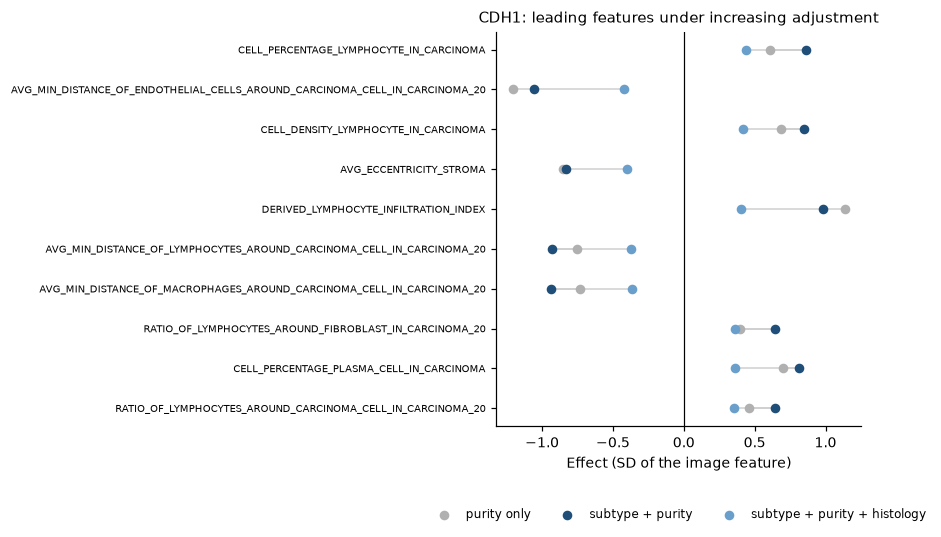

,comparison,feature,n,n_altered,effect,ci_low,ci_high,p,expected,matches_expected
0,"CDH1 mutation, whole cohort (+ histology)",RATIO_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,903,110,-0.226,-0.439,-0.014,0.037,down,True
1,"CDH1 mutation, whole cohort (+ histology)",AVG_MIN_DISTANCE_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,903,110,0.163,-0.068,0.393,0.166,up,True
2,"CDH1 mutation, whole cohort (+ histology)",RATIO_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_STROMA_20,903,110,-0.054,-0.262,0.154,0.608,up,False
3,Two hits vs other lobular,RATIO_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,129,78,-0.246,-0.552,0.060,0.114,down,True
4,Two hits vs other lobular,AVG_MIN_DISTANCE_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,129,78,-0.153,-0.514,0.207,0.401,up,False
5,Two hits vs other lobular,RATIO_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_STROMA_20,129,78,-0.025,-0.359,0.310,0.883,up,False
6,"16q loss alone vs none, ductal (negative control)",RATIO_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,537,327,-0.047,-0.195,0.101,0.530,None,NaN
7,"16q loss alone vs none, ductal (negative control)",AVG_MIN_DISTANCE_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,537,327,0.039,-0.116,0.193,0.624,None,NaN
8,"16q loss alone vs none, ductal (negative control)",RATIO_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_STROMA_20,537,327,0.045,-0.096,0.187,0.529,None,NaN


In [14]:
if PC:
    pc_name, pc_mut, pc_hist = PC["name"], PC["mutation"], PC["histology"]
    pc_rationale = next((s["rationale"] for s in SELECTED if s["variable"] == pc_mut), "")
    print(pc_rationale)
    pc_effects = show_footprint(pc_name, pc_mut)

    cohesion_expected = PC["features"]
    cohesion_features = [f for f in cohesion_expected if f in df.columns]
    identity = {f: f for f in cohesion_features}
    typical, other, arm = PC["typical_histology"], PC["other_histology"], PC["arm_loss"]
    comparisons = {
        f"{pc_name} mutation, whole cohort (+ histology)": MolecularTarget(
            f"{pc_name} mutation", pc_mut, extra_covariates=[pc_hist], expected=cohesion_expected),
        f"Two hits vs other {typical}": MolecularTarget(
            f"{pc_name} two hits ({typical})", PC["two_hit"], cohort=f"{pc_hist} == '{typical}'",
            expected=cohesion_expected),
        f"{PC['arm_label']} alone vs none, {other} (negative control)": MolecularTarget(
            f"{PC['arm_label']} ({other}, {pc_name} wild type)", arm,
            cohort=f"{pc_hist} == '{other}' and {pc_mut} == 0"),
    }
    pc_checks = pd.concat(
        [tissue_footprint(df, t, cohesion_features, identity, COVARIATES, transform=TRANSFORM).assign(comparison=label)
         for label, t in comparisons.items()], ignore_index=True)
    pc_checks.to_csv(OUT_DIR / "positive_control_checks.csv", index=False)
    with pd.option_context("display.max_colwidth", None):
        display(pc_checks[["comparison", "feature", "n", "n_altered", "effect", "ci_low", "ci_high", "p",
                           "expected", "matches_expected"]].round(3))
else:
    print("No positive control configured for this indication.")

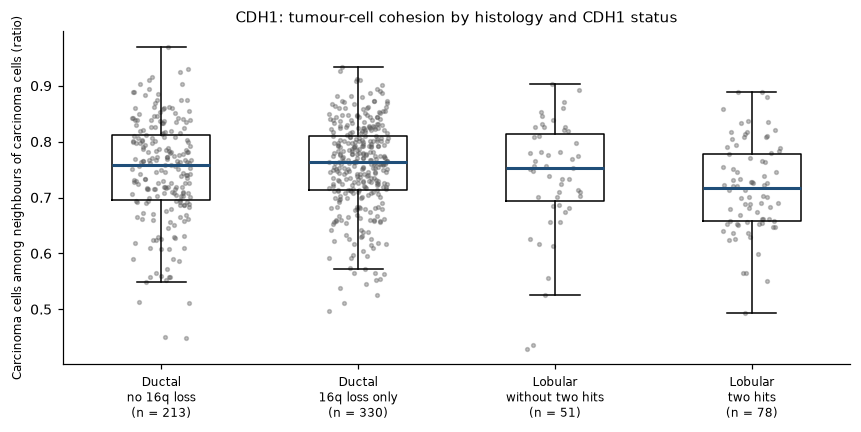

In [15]:
# First cohesion feature across the four groups of the comparisons above
if PC:
    feature = cohesion_features[0]
    group = pd.Series(np.nan, index=df.index, dtype="object")
    other_wt = (df[pc_hist] == other) & (df[pc_mut] == 0)
    names = [f"{other.capitalize()}\nno {PC['arm_label']}", f"{other.capitalize()}\n{PC['arm_label']} only",
             f"{typical.capitalize()}\nwithout two hits", f"{typical.capitalize()}\ntwo hits"]
    group[other_wt & (df[arm] == 0)] = names[0]
    group[other_wt & (df[arm] == 1)] = names[1]
    group[(df[pc_hist] == typical) & (df[PC["two_hit"]] == 0)] = names[2]
    group[(df[pc_hist] == typical) & (df[PC["two_hit"]] == 1)] = names[3]
    df["positive_control_group"] = group

    fig = plot_feature_by_group(df, feature, "positive_control_group", names, ylabel=PC.get("plot_ylabel", feature),
                                title=f"{pc_name}: tumour-cell cohesion by histology and {pc_name} status")
    fig.savefig(FIGS / "positive_control_by_group.png", bbox_inches="tight")
    plt.show()

### 4.2 Other selected footprints

The remaining footprints of `selected_footprints` (breast: tumour mutational burden, TP53 and aneuploidy, the strongest footprints of genomic instability), each with the reason it was selected.


Tumour mutational burden (thor_tmb_log10): Neoantigens from a high mutational burden can attract immune cells: a footprint in the immune compartment is the expected reading.


adjustment,purity only,subtype + purity,subtype + purity + histology,q (subtype + purity + histology)
feature,,,,
AVG_MIN_DISTANCE_OF_ENDOTHELIAL_CELLS_AROUND_MACROPHAGE_IN_STROMA_20,0.250,0.179,0.182,0.000
CELL_PERCENTAGE_LYMPHOCYTE_IN_CARCINOMA,0.194,0.137,0.175,0.000
CELL_PERCENTAGE_MACROPHAGE_IN_CARCINOMA,0.305,0.168,0.172,0.000
RATIO_OF_LYMPHOCYTES_AROUND_PLASMA_CELL_IN_CARCINOMA_20,0.216,0.150,0.166,0.000
RATIO_OF_LYMPHOCYTES_AROUND_CARCINOMA_CELL_IN_STROMA_20,0.250,0.163,0.165,0.000
RATIO_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,0.350,0.193,0.159,0.000
RATIO_OF_LYMPHOCYTES_AROUND_LYMPHOCYTE_IN_CARCINOMA_20,0.188,0.141,0.158,0.000
RATIO_OF_LYMPHOCYTES_AROUND_GRANULOCYTE_IN_CARCINOMA_20,0.181,0.139,0.157,0.000
RATIO_OF_LYMPHOCYTES_AROUND_FIBROBLAST_IN_CARCINOMA_20,0.199,0.135,0.157,0.000


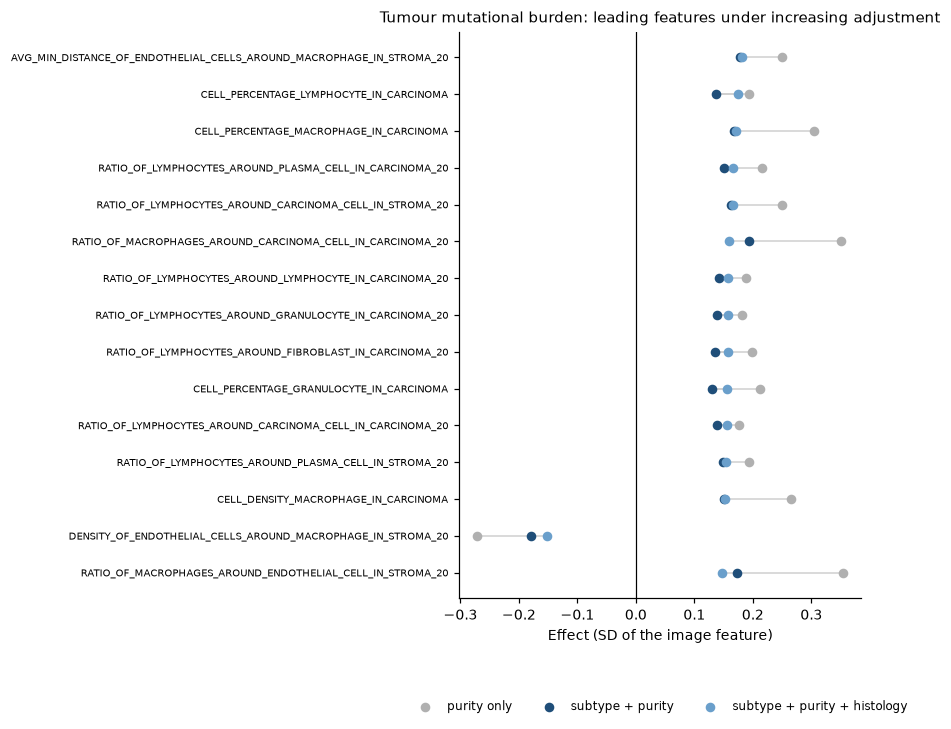


TP53 (mut_TP53): TP53 mutations are concentrated in basal-like tumours, so most of their apparent footprint is expected to disappear with adjustment for subtype.


adjustment,purity only,subtype + purity,subtype + purity + histology,q (subtype + purity + histology)
feature,,,,
RATIO_OF_MACROPHAGES_AROUND_PLASMA_CELL_IN_CARCINOMA_20,0.880,0.466,0.395,0.000
DENSITY_OF_MACROPHAGES_AROUND_PLASMA_CELL_IN_CARCINOMA_20,0.924,0.486,0.393,0.000
CELL_PERCENTAGE_ENDOTHELIAL_CELL_IN_STROMA,-0.729,-0.400,-0.387,0.000
RATIO_OF_MACROPHAGES_AROUND_ENDOTHELIAL_CELL_IN_CARCINOMA_20,0.914,0.460,0.378,0.000
RATIO_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,0.825,0.461,0.376,0.000
RATIO_OF_ENDOTHELIAL_CELLS_AROUND_LYMPHOCYTE_IN_STROMA_20,-0.792,-0.415,-0.368,0.001
RATIO_OF_ENDOTHELIAL_CELLS_AROUND_PLASMA_CELL_IN_STROMA_20,-0.876,-0.412,-0.365,0.000
RATIO_OF_ENDOTHELIAL_CELLS_AROUND_MACROPHAGE_IN_STROMA_20,-0.775,-0.438,-0.364,0.001
RATIO_OF_MACROPHAGES_AROUND_CARCINOMA_CELL_IN_STROMA_20,1.003,0.467,0.363,0.000


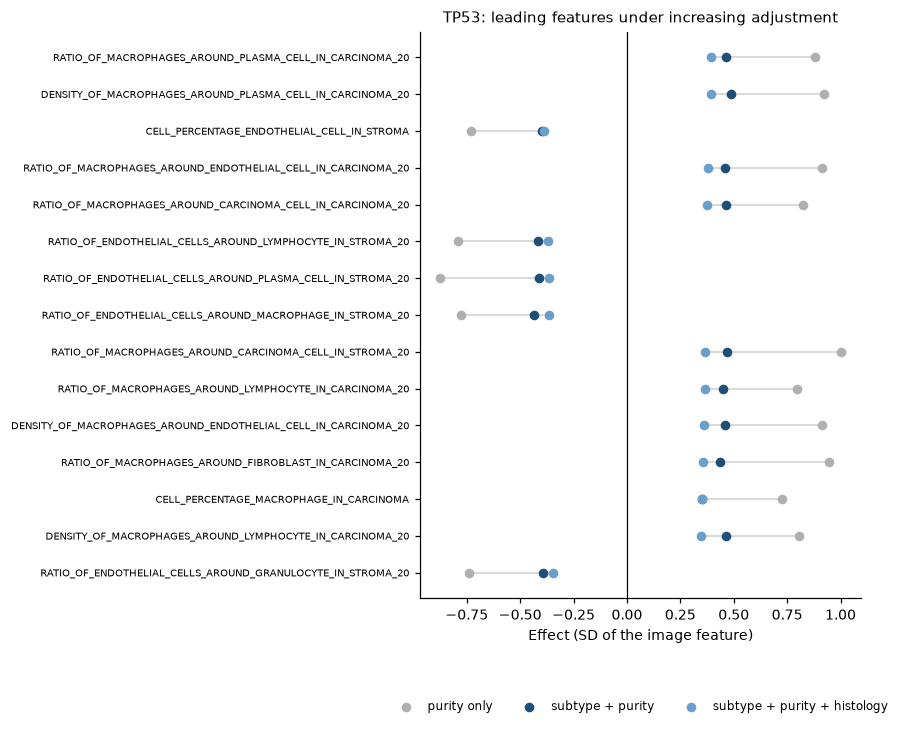


Aneuploidy (thor_aneuploidy_score): Aneuploid tumour cells carry more DNA (larger nuclei expected), and chromosomal instability has been associated with reduced immune infiltration across cancers (Davoli et al. 2017).


adjustment,purity only,subtype + purity,subtype + purity + histology,q (subtype + purity + histology)
feature,,,,
NUCLEUS_AVG_AREA_CARCINOMA_CELL,0.310,0.215,0.203,0.0
CELL_DENSITY_CARCINOMA_CELL_IN_CARCINOMA,-0.250,-0.180,-0.197,0.0
AVG_MIN_DISTANCE_OF_CARCINOMA_CELLS_AROUND_CARCINOMA_CELL_IN_CARCINOMA_20,0.249,0.179,0.196,0.0
AVG_MIN_DISTANCE_OF_CARCINOMA_CELLS_AROUND_LYMPHOCYTE_IN_CARCINOMA_20,0.229,0.170,0.186,0.0
NUCLEUS_AVG_MAJ_AXIS,0.190,0.190,0.183,0.0
DENSITY_OF_CARCINOMA_CELLS_AROUND_LYMPHOCYTE_IN_CARCINOMA_20,-0.165,-0.159,-0.177,0.0
AVG_MIN_DISTANCE_OF_CARCINOMA_CELLS_AROUND_ENDOTHELIAL_CELL_IN_CARCINOMA_20,0.183,0.149,0.170,0.0
DENSITY_OF_CARCINOMA_CELLS_AROUND_GRANULOCYTE_IN_CARCINOMA_20,-0.149,-0.142,-0.162,0.0
RATIO_OF_MACROPHAGES_AROUND_LYMPHOCYTE_IN_CARCINOMA_20,0.319,0.180,0.162,0.0


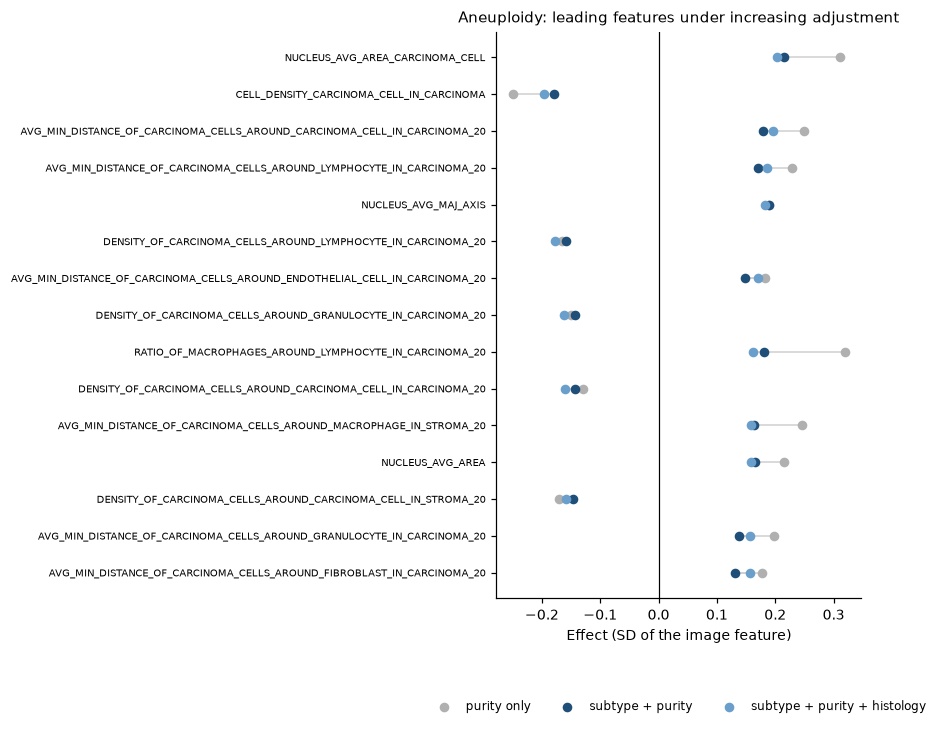

In [16]:
selected_results = {}
for s in SELECTED:
    if PC and s["variable"] == PC["mutation"]:
        continue  # shown as the positive control
    print(f"\n{s['name']} ({s['variable']}): {s['rationale']}")
    selected_results[s["name"]] = show_footprint(s["name"], s["variable"])